<a href="https://colab.research.google.com/github/ClaudiaSorto-006/programacionIII_2026/blob/Uso-de-Librerias/_librerias_panda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

In [ ]:
import pandas as pd

# Corregido: Usamos el archivo existente en tu entorno de Colab
archivo = "/content/Usar librerias-reguistros.csv"
notas = pd.read_csv(archivo, sep=";", encoding="utf-8")
notas.head()

,nombre,nota
0,Luis,6
1,Juan,8
2,Maria,9
3,Jose,10
4,Oscar,4


In [ ]:
# Eliminamos espacios en blanco ocultos en los nombres de las columnas
notas.columns = notas.columns.str.strip()

# Ahora podemos agrupar de forma segura usando la columna 'nombre'
notas_alumnos = notas.groupby(["nota"]).agg({'nombre': lambda n: ', '.join(map(str, n))})
print(notas_alumnos)

               nombre
nota                 
2              Mario 
4     Oscar, Daniela 
5               Pedro
6               Luis 
7             Carmen 
8               Juan 
9       Maria , Ramon
10              Jose 


In [ ]:
cantidad_aprobados = notas.loc[notas["nota"] >= 6].agg({"nota": "count"})
cantidad_reprobados = notas.loc[notas["nota"] < 6].agg({"nota": "count"})

print("Cantidad de alumnos aprobados", cantidad_aprobados)
print("Cantidad de alumnos reprobados", cantidad_reprobados)


Cantidad de alumnos aprobados nota    6
dtype: int64
Cantidad de alumnos reprobados nota    4
dtype: int64


In [ ]:
cantidad_aprobados = notas.loc[notas["nota"] >= 6, "nota"].count()
cantidad_reprobados = notas.loc[notas["nota"] < 6, "nota"].count()

print("Cantidad de alumnos aprobados:", cantidad_aprobados)
print("Cantidad de alumnos reprobados:", cantidad_reprobados)

Cantidad de alumnos aprobados: 6
Cantidad de alumnos reprobados: 4


In [ ]:
# importar la libreria para graficos
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
notas['estado'] = notas['nota'].apply(lambda x: 'Aprobado' if x >= 6 else 'Reprobado')
notas


,nombre,nota,estado
0,Luis,6,Aprobado
1,Juan,8,Aprobado
2,Maria,9,Aprobado
3,Jose,10,Aprobado
4,Oscar,4,Reprobado
5,Pedro,5,Reprobado
6,Ramon,9,Aprobado
7,Carmen,7,Aprobado
8,Mario,2,Reprobado
9,Daniela,4,Reprobado


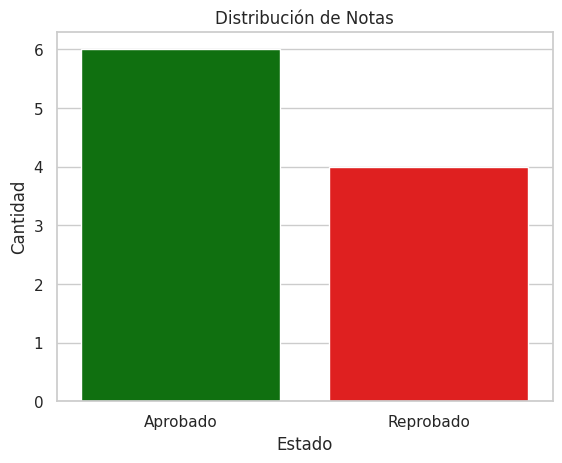

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
# Solución recomendada: asignar 'x' también a 'hue' y desactivar la leyenda (legend=False)
sns.countplot(x="estado", hue="estado", data=notas, palette={'Aprobado': 'green', 'Reprobado': 'red'}, legend=False)
plt.title("Distribución de Notas")
plt.xlabel("Estado")
plt.ylabel("Cantidad")
plt.show()

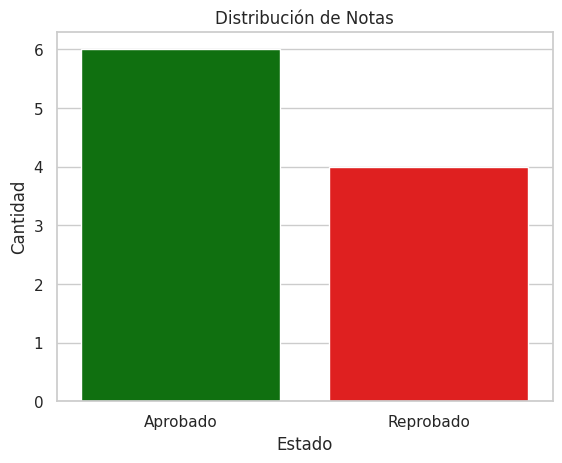

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
sns.countplot(
    x="estado",
    data=notas,
    hue="estado",
    palette={'Aprobado': 'green', 'Reprobado': 'red'},
    legend=False
)
plt.title("Distribución de Notas")
plt.xlabel("Estado")
plt.ylabel("Cantidad")
plt.show()

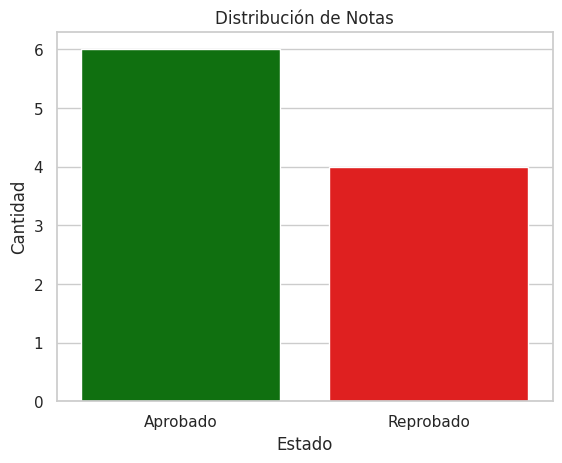

In [ ]:
sns.set(style="whitegrid")
sns.countplot(
    x="estado",
    data=notas,
    hue="estado",
    palette={'Aprobado': 'green', 'Reprobado':'red'}
)
plt.title("Distribución de Notas")
plt.xlabel("Estado")
plt.ylabel("Cantidad")
plt.show()


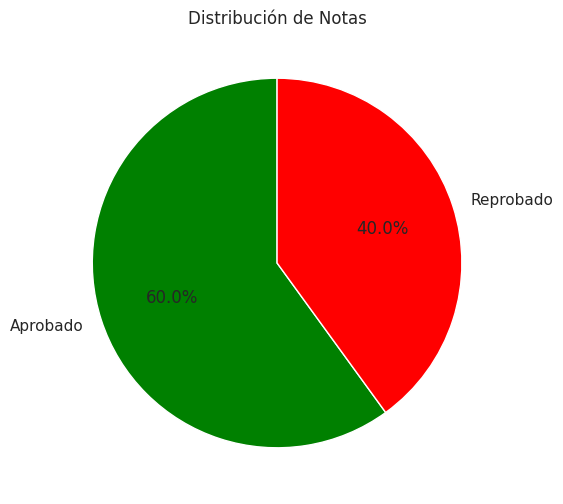

In [ ]:
conteo = notas["estado"].value_counts()
colores = {'Aprobado': 'green', 'Reprobado': 'red'}

plt.figure(figsize=(6, 6))
plt.pie(
    conteo,
    labels=conteo.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=[colores[estado] for estado in conteo.index]
)
plt.title("Distribución de Notas")
plt.show()

In [ ]:
import tensorflow as tf
import numpy as np

celsius = np.array([-40, -10, 0, 8, 15, 22, 38], dtype=float)
salida = np.array([
    [-40.0, 233.15],
    [14.0, 263.15],
    [32.0, 273.15],
    [46.4, 281.15],
    [59.0, 288.15],
    [71.6, 295.15],
    [100.4, 311.15]
], dtype=float)

modelo = tf.keras.Sequential([
    tf.keras.Input(shape=(1,)),
    tf.keras.layers.Dense(units=2)
])

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(0.5),
    loss='mean_squared_error'
)

modelo.fit(celsius, salida, epochs=1000, verbose=False)

resultado = modelo.predict(np.array([100.0]))
print(f"Fahrenheit: {resultado[0][0]:.2f} °F")
print(f"Kelvin: {resultado[0][1]:.2f} K")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
Fahrenheit: 212.00 °F
Kelvin: 371.33 K
